In [1]:
import matplotlib.pyplot as plt
import random

In [2]:
#total population
N = 1000
#people infected
I0 = 10
#in contact with
K = 8
#infected chance
T = 0.03
#dying
L = 0.01
#recovery
P = 0.08

days = 100

In [3]:
S = N - I0
I = I0
R = 0
D = 0

In [4]:
#list to store future values

S_list = [S]
D_list = [D]
R_list = [R]
I_list = [I]

Thought process and how it works:

for each day:
    for each infected person:
        for each contact:
            maybe infect someone
    
    for each infected person:
        maybe die
        maybe recover


In [13]:
for day in range(days):
    new_recoveries = 0
    new_deaths = 0
    new_infections = 0


    
    for _ in range(I):
        for _ in range(K):
            if S > 0 and random.random() < T:
                new_infections += 1
        
    
    
    #take amount of people susceptible and subtract from it new infections
    S -= new_infections
    
    for _ in range(I):
        if random.random() < L:
            new_deaths += 1
        elif random.random() < P:
            new_recoveries += 1
                
    I = I + new_infections - new_recoveries- new_deaths
    R += new_recoveries
    D += new_deaths
    
    
    #add values to list to later plot, updates everyday in this loop
    
    S_list.append(S)
    D_list.append(D)
    R_list.append(R)
    I_list.append(I)

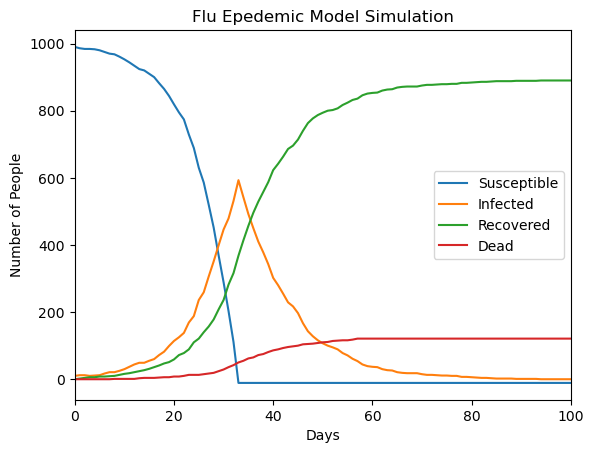

In [ ]:
plt.plot(S_list, label="Susceptible")
plt.plot(I_list, label="Infected")
plt.plot(R_list, label="Recovered")
plt.plot(D_list, label="Dead")

plt.xlabel("Days")
plt.ylabel("Number of People")
plt.title("Flu Epidemic Model Simulation")
plt.xlim(0,100)
plt.legend()
plt.show()

## Add vaccine paramater to model

In [11]:
#vaccine variable
V = 0.1


V_list = []

Below I test multiple vaccination rates. I found that using an axes object would be the better route to take for plotting multiple different plots for different vaccination rates. I learned what a fig and ax was(the entire figure, the individual graph inside the figure) and also what an axes was(an array of axes objects).

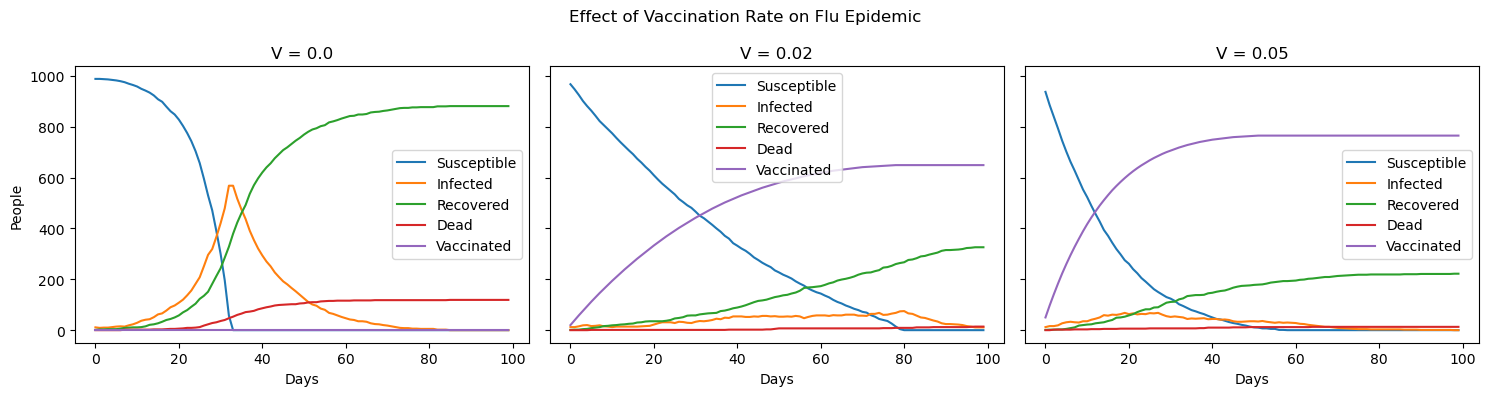

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, V in zip(axes, [0.0, 0.02, 0.05]):
    # reset everything
    S = N - I0
    I = I0
    R = 0
    D = 0
    total_vaccinated = 0
    S_list = []
    I_list = [] 
    R_list = [] 
    D_list = []
    V_list = []

    for day in range(days):
        new_recoveries = 0
        new_deaths = 0
        new_infections = 0

        #percent of people vaccinated out of population
        vaccinated_fraction = total_vaccinated / N
        #transmission of flu after vaccine
        T_eff = T * (1 - vaccinated_fraction)
        #death measurement after vaccination
        L_eff = L * (1 - vaccinated_fraction)

        for _ in range(I):
            for _ in range(K):
                if S > 0 and random.random() < T_eff:
                    new_infections += 1

        new_vaccinated = round(S * V)
        new_infections = min(new_infections, S)
        new_vaccinated = min(new_vaccinated, S - new_infections)

        S -= new_infections + new_vaccinated
        total_vaccinated += new_vaccinated

        for _ in range(I):
            if random.random() < L_eff:
                new_deaths += 1
            elif random.random() < P:
                new_recoveries += 1

        I = I + new_infections - new_recoveries - new_deaths
        R += new_recoveries
        D += new_deaths

        S_list.append(S)
        I_list.append(I)
        R_list.append(R)
        D_list.append(D)
        V_list.append(total_vaccinated)

    ax.plot(S_list, label='Susceptible')
    ax.plot(I_list, label='Infected')
    ax.plot(R_list, label='Recovered')
    ax.plot(D_list, label='Dead')
    ax.plot(V_list, label='Vaccinated')
    ax.set_title(f'V = {V}')
    ax.set_xlabel('Days')
    ax.legend()

axes[0].set_ylabel('People')
plt.suptitle('Effect of Vaccination Rate on Flu Epidemic')
plt.tight_layout()
plt.show()